# Lab 1.1 · Platform tour

Day 1 · Session 1 · 25 min. What you'll do:
- get your setup running in a second tab while you tour Qafila's sources;
- follow order 5043883 through the records it left behind;
- find the first problems in the data and write them down in an **issue log**.

**Tasks**
- [ ] 1 · Run 00_setup_check in a second tab (3')
- [ ] 2 · Tour the sources without loading anything (5')
- [ ] 3 · Follow order 5043883 through four tables (5')
- [ ] 4 · Count orders per day in Riyadh time (5')
- [ ] 5 · Find the problems and write the issue log (7')
- [ ] ✱ Stretch · Explain the biggest day of the two months

Please don't open `data/raw/DATA_ISSUES.txt` yet: finding the issues is the exercise.

In [1]:
import os, sys, subprocess
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    REPO_URL = "https://github.com/SDAIAAcademy/data-engineering.git"
    if not Path("/content/data-engineering").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/data-engineering"], check=True)
    os.chdir("/content/data-engineering/labs")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
else:
    while not Path("de_utils.py").exists() and Path.cwd() != Path.cwd().parent:
        os.chdir("..")  # solutions/ notebooks run from labs/
sys.path.insert(0, os.getcwd())

import de_utils as U
U.ensure_data()
print("data:", U.RAW, "| quick mode:", U.QUICK)

data: /content/data-engineering/labs\data\raw | quick mode: False


## 1 · Run 00_setup_check in a second tab (3')

Open the setup check in a **second tab** and press *Run all*. It takes 2–5 minutes, so leave it running and carry on here.

- On Colab: [open 00_setup_check.ipynb](https://colab.research.google.com/github/SDAIAAcademy/data-engineering/blob/main/labs/00_setup_check.ipynb)
- On your laptop: [00_setup_check.ipynb](00_setup_check.ipynb), next to this notebook

It installs the packages, generates Qafila's data and tests every tool of the week. When it finishes, every line
should show ✅ (PySpark is optional). If one shows ❌, tell the instructor now, not on Day 4.

## 2 · Tour the sources without loading anything (5')

Below is the whole platform you will build this week. Today you are at the far left: the sources.

In [2]:
import duckdb
import matplotlib.pyplot as plt
import de_viz as V

V.platform_map(stage="sources")

Every step of an order leaves a record in a different system:

| Record | Source system | Where it is here | Format |
|---|---|---|---|
| orders, order lines, customers, stores, products | the app database | `data/raw/qafila_oltp.sqlite` | SQLite tables |
| payments | payment provider's API | `data/raw/api/payments.jsonl` | JSON lines |
| delivery events | courier app | `data/raw/events/delivery_events.jsonl` | JSON lines |
| customer changes | app database's change feed | `data/raw/cdc/customers_changes.jsonl` | JSON lines |
| supplier price lists | one file per week | `data/raw/suppliers/prices_2026-W*.csv` | CSV |
| reviews | written in the app | `data/raw/reviews.csv` | CSV |

**JSON lines** is one JSON object per line of a text file. Look at a raw file with your own eyes first:

In [3]:
U.peek(U.RAW / "events" / "delivery_events.jsonl", 2)
print()
U.peek(U.RAW / "reviews.csv", 3)

{"event_id": "ev-0001457", "order_id": 5040442, "store_id": "JED-01", "city": "Jeddah", "courier_id": "CR-JED-031", "event_type": "assigned", "event_time": "2026-09-24T05:14:52.016+03:00", "lat": 21.58424, "lon": 39.1723 …
{"event_id": "ev-0001458", "order_id": 5040442, "store_id": "JED-01", "city": "Jeddah", "courier_id": "CR-JED-031", "event_type": "picked_up", "event_time": "2026-09-24T05:24:21.703+03:00", "lat": 21.53236, "lon": 39.166 …

review_id,product_id,customer_id,rating,lang,review_text,created_at
700000,1022,102460,5,en,Best greek yogurt family size I have bought online,2026-09-06 06:09:14
700001,1163,104002,4,en,"Good quality, packaging could be better",2026-09-06 12:43:12


**DuckDB** is the SQL engine you will use all week (next session explains why it is so fast). It runs inside this
notebook, with nothing to install or start, and it reads each source **where it is**: a file path works as a table.

In [4]:
con = duckdb.connect()          # an in-memory database: nothing is copied unless we ask
con.sql("SET enable_progress_bar = false")
RAW = U.RAW.as_posix()          # DuckDB likes forward slashes, also on Windows
EVENTS = f"read_json_auto('{RAW}/events/delivery_events.jsonl')"
PAYMENTS = f"read_json_auto('{RAW}/api/payments.jsonl', sample_size = -1)"   # read the whole file to find all columns

con.sql(f"SELECT * FROM read_csv('{RAW}/reviews.csv') LIMIT 3")

review_idBIGINT,product_idBIGINT,customer_idBIGINT,ratingBIGINT,langVARCHAR,review_textVARCHAR,created_atTIMESTAMP
700000,1022,102460,5,en,Best greek yogurt family size I have bought online,2026-09-06 06:09:14
700001,1163,104002,4,en,"Good quality, packaging could be better",2026-09-06 12:43:12
700002,1301,102999,1,ar,المنتج منتهي الصلاحية,2026-08-17 01:07:55


In [5]:
U.attach_app(con)               # the app database, attached read-only as `app`
sizes = {t: con.sql(f"SELECT count(*) FROM app.{t}").fetchall()[0][0]
         for t in ["customers", "stores", "products", "orders", "order_items"]}
sizes

{'customers': 7442,
 'stores': 12,
 'products': 356,
 'orders': 45766,
 'order_items': 172545}

✏️ **Exercise 1** · Count the delivery events per `event_type`, straight from the JSON lines file, largest first.
The file is already in the variable `EVENTS`, so the query starts `FROM {EVENTS}`. Replace the `raise` line.
Hint: this is a plain `GROUP BY` and `ORDER BY n DESC`, with `count(*) AS n`.

In [6]:
def events_by_type():
    # return con.sql(f"SELECT event_type, count(*) AS n FROM {EVENTS} GROUP BY ___ ORDER BY ___")
    return con.sql(f"SELECT event_type, count(*) AS n FROM {EVENTS} GROUP BY event_type ORDER BY n DESC")

In [7]:
try:
    by_type = events_by_type()
    total = sum(n for _, n in by_type.fetchall())
    U.check(by_type.columns == ["event_type", "n"], "columns are event_type, n")
    U.check(total == 22518, f"{total:,} events in total")
except NotImplementedError:
    print("⏭️ Exercise 1 not done yet. Expected: six event types, 22,518 events in total. Using the reference result.")
    by_type = con.sql(f"SELECT event_type, count(*) AS n FROM {EVENTS} GROUP BY 1 ORDER BY 2 DESC")
by_type

✅ columns are event_type, n
✅ 22,518 events in total


event_typeVARCHAR,nBIGINT
assigned,5770
picked_up,5493
out_for_delivery,5490
delivered,5327
cancelled,278
failed,160


🔍 **Look at** the counts. An order that goes well sends four events: `assigned`, `picked_up`, `out_for_delivery`,
`delivered`. Why are there more `assigned` than `delivered`?

## 3 · Follow order 5043883 through four tables (5')

Khalid in Al Malqa, Riyadh, ordered cucumbers and coffee. One `order_id` ties his records together: it is the **key**.

In [8]:
ORDER = 5043883
con.sql(f"SELECT order_id, status, customer_id, store_id, delivery_fee, created_at, updated_at FROM app.orders WHERE order_id = {ORDER}")

order_idBIGINT,statusVARCHAR,customer_idBIGINT,store_idVARCHAR,delivery_feeDOUBLE,created_atVARCHAR,updated_atVARCHAR
5043883,delivered,107371,RUH-05,9.0,2026-09-27 22:35:37,2026-09-27 23:07:37


In [9]:
con.sql(f"SELECT order_id, line_no, product_id, quantity, unit_price FROM app.order_items WHERE order_id = {ORDER}")

order_idBIGINT,line_noBIGINT,product_idBIGINT,quantityBIGINT,unit_priceDOUBLE
5043883,1,1104,1,4.74
5043883,2,1193,2,37.88


In [10]:
con.sql(f"SELECT payment_id, order_id, amount, method, status FROM {PAYMENTS} WHERE order_id = {ORDER}")

payment_idVARCHAR,order_idBIGINT,amountDOUBLE,methodVARCHAR,statusVARCHAR
pay_9040078,5043883,89.5,card,captured


In [11]:
con.sql(f"SELECT event_type, event_time, courier_id, order_id FROM {EVENTS} WHERE order_id = {ORDER}")

event_typeVARCHAR,event_timeVARCHAR,courier_idVARCHAR,order_idBIGINT
assigned,2026-09-28T01:36:34.531+03:00,CR-RIY-076,5043883
picked_up,2026-09-28T01:46:49.189+03:00,CR-RIY-076,5043883
out_for_delivery,2026-09-28T01:48:20.714+03:00,CR-RIY-076,5043883
delivered,2026-09-28T01:54:55.084+03:00,CR-RIY-076,5043883


🔍 **Look at** the four results. Eight rows: one order, two lines, one payment, four events.
- **State or events?** The order row says only `delivered`: each new status overwrote the old one. The events keep every step.
- **Two clocks.** `created_at` says 27 September 22:35 (UTC). The first event says 28 September 01:36 (`+03:00`, Riyadh).

Other keys name who and what. Follow them with a join:

In [12]:
con.sql(f"""
    SELECT o.order_id, c.full_name, c.district, s.name_en AS store, p.name_en AS product, i.quantity,
           i.quantity * i.unit_price - i.discount AS amount
    FROM app.orders o
    JOIN app.customers c USING (customer_id)
    JOIN app.stores s USING (store_id)
    JOIN app.order_items i USING (order_id)
    JOIN app.products p USING (product_id)
    WHERE o.order_id = {ORDER}
""")

order_idBIGINT,full_nameVARCHAR,districtVARCHAR,storeVARCHAR,productVARCHAR,quantityBIGINT,amountDOUBLE
5043883,خالد التميمي,Al Malqa,Qafila Al Naseem,Sahra Cucumbers,1,4.74
5043883,خالد التميمي,Al Malqa,Qafila Al Naseem,Al Waha Arabic Coffee,2,75.76


## 4 · Count orders per day in Riyadh time (5')

The app stores UTC as text, and the business counts days in Riyadh time (UTC+3). Khalid's order belongs to 28 September,
not 27. Grouping by the UTC date puts every order after 21:00 UTC on the wrong day.

✏️ **Exercise 2** · One row per **Riyadh** day: columns `day` and `orders`, ordered by day.
Hint: `created_at` is text, so `created_at::TIMESTAMP` makes it a time, `+ INTERVAL 3 HOUR` moves it to Riyadh, and `::DATE` keeps the day.

In [13]:
def daily_orders():
    # return con.sql("SELECT (created_at::TIMESTAMP + ___)::DATE AS day, count(*) AS orders FROM app.orders GROUP BY day ORDER BY day")
    return con.sql("SELECT (created_at::TIMESTAMP + INTERVAL 3 HOUR)::DATE AS day, count(*) AS orders FROM app.orders GROUP BY day ORDER BY day")

✅ 61 days, 1 August to 30 September, counted in Riyadh time


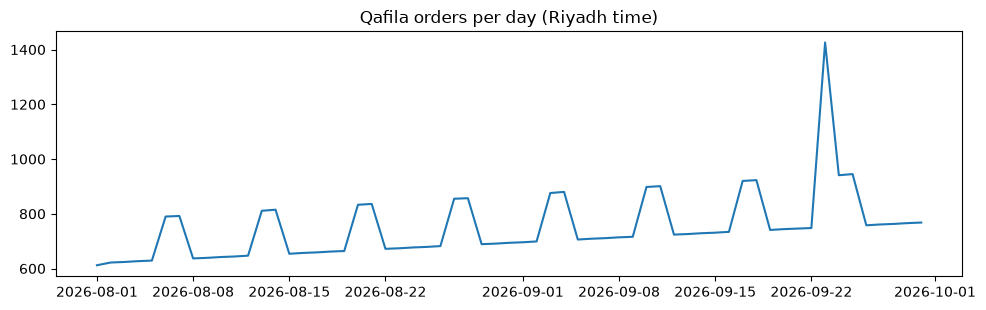

In [14]:
REF_DAILY = "SELECT (created_at::TIMESTAMP + INTERVAL 3 HOUR)::DATE AS day, count(*) AS orders FROM app.orders GROUP BY day ORDER BY day"
try:
    daily = daily_orders()
    U.check(con.sql(REF_DAILY).fetchall() == daily.fetchall(), "61 days, 1 August to 30 September, counted in Riyadh time")
except NotImplementedError:
    print("⏭️ Exercise 2 not done yet. Expected: 61 rows, one per day. Using the reference result.")
    daily = con.sql(REF_DAILY)

days, counts = zip(*daily.fetchall())
plt.figure(figsize=(10, 3.2))
plt.plot(days, counts)
plt.title("Qafila orders per day (Riyadh time)")
plt.tight_layout()
plt.show()

🔍 **Look at** the chart: a weekly rhythm, slow growth, and one day that stands out (the ✱ Stretch).

## 5 · Find the problems and write the issue log (7')

A primary key guarantees that the **ID** is unique, not that each **person** appears once. Run these checks and read them.

In [15]:
dup_people = con.sql("SELECT count(*) FROM (SELECT national_id FROM app.customers GROUP BY 1 HAVING count(*) > 1)").fetchall()[0][0]
negative_lines = con.sql("SELECT count(*) FROM app.order_items WHERE quantity < 0").fetchall()[0][0]
duplicate_events = con.sql(f"SELECT count(*) - count(DISTINCT event_id) FROM {EVENTS}").fetchall()[0][0]
print(f"people with several accounts: {dup_people} | negative order lines: {negative_lines} | repeated events: {duplicate_events}")

con.sql("""
    SELECT customer_id, full_name, email, mobile, national_id
    FROM app.customers
    WHERE national_id = (SELECT national_id FROM app.customers GROUP BY 1 HAVING count(*) > 1 ORDER BY 1 LIMIT 1)
""")

people with several accounts: 58 | negative order lines: 142 | repeated events: 312


customer_idBIGINT,full_nameVARCHAR,emailVARCHAR,mobileVARCHAR,national_idVARCHAR
100162,بندر الجهني,bandar.148@icloud.com,0596390578,1118790243
106058,بندر الجهني,BANDAR.148@ICLOUD.COM,+966 50 525 5034,1118790243


🔍 Same person, same national ID, but the email is upper-cased and the mobile is written differently. `DISTINCT` on the email would miss it.

Formats are where integrations break. The same mobile number, and the same event time, written several ways:

In [16]:
con.sql(r"""
    SELECT CASE WHEN regexp_full_match(mobile, '\+9665\d{8}')           THEN '+9665XXXXXXXX'
                WHEN regexp_full_match(mobile, '05\d{8}')               THEN '05XXXXXXXX'
                WHEN regexp_full_match(mobile, '9665\d{8}')             THEN '9665XXXXXXXX'
                WHEN regexp_full_match(mobile, '\+966 5\d \d{3} \d{4}') THEN '+966 5X XXX XXXX'
                ELSE 'other' END AS mobile_format,
           count(*) AS n
    FROM app.customers GROUP BY ALL ORDER BY n DESC
""")

mobile_formatVARCHAR,nBIGINT
+9665XXXXXXXX,3350
05XXXXXXXX,2251
+966 5X XXX XXXX,1072
9665XXXXXXXX,766
other,3


In [17]:
con.sql(rf"""
    SELECT CASE WHEN event_time LIKE '%+03:00'                 THEN 'ISO with +03:00'
                WHEN event_time LIKE '%Z'                      THEN 'ISO with Z (UTC)'
                WHEN regexp_full_match(event_time, '\d{{13}}') THEN 'milliseconds since 1970'
                ELSE 'other' END AS time_format,
           count(*) AS n
    FROM {EVENTS} GROUP BY ALL ORDER BY n DESC
""")

time_formatVARCHAR,nBIGINT
ISO with +03:00,18031
ISO with Z (UTC),3372
milliseconds since 1970,1115


In [18]:
for week in ["W37", "W38", "W39"]:
    cols = con.sql(f"SELECT column_name, column_type FROM (DESCRIBE FROM read_csv('{RAW}/suppliers/prices_2026-{week}.csv'))")
    print(week, {name: kind for name, kind in cols.fetchall() if "cost" in name or name == "currency"})

W37 {'unit_cost': 'DOUBLE'}
W38 {'unit_cost': 'VARCHAR'}
W39 {'cost_sar': 'DOUBLE', 'currency': 'VARCHAR'}


🔍 Week 37: `unit_cost` is a number. Week 38: the same column is text, because the supplier's Excel wrote decimal commas
(`9,49`) and some Arabic digits. Week 39: `unit_cost` is gone and `cost_sar` appeared. Nobody told us. A source changing
its columns without warning is called **schema drift**.

✏️ **Exercise 3** · Count the orders whose `customer_id` has no row in `app.customers`: these are **orphan orders**.
Hint: a `LEFT JOIN` keeps every order and fills the customer's columns with `NULL` when no row matches.

In [19]:
def count_orphan_orders():
    # return con.sql("SELECT count(*) FROM app.orders o LEFT JOIN app.customers c USING (customer_id) WHERE ___").fetchall()[0][0]
    return con.sql("SELECT count(*) FROM app.orders o LEFT JOIN app.customers c USING (customer_id) WHERE c.customer_id IS NULL").fetchall()[0][0]

In [20]:
REF_ORPHANS = "SELECT count(*) FROM app.orders WHERE customer_id NOT IN (SELECT customer_id FROM app.customers)"
try:
    orphan_orders = count_orphan_orders()
    U.check(orphan_orders == con.sql(REF_ORPHANS).fetchall()[0][0], f"{orphan_orders:,} orphan orders")
except NotImplementedError:
    orphan_orders = con.sql(REF_ORPHANS).fetchall()[0][0]
    print(f"⏭️ Exercise 3 not done yet. Expected: {orphan_orders:,} orphan orders. Using the reference result.")

✅ 1,040 orphan orders


🔍 Those customers asked to be erased under the PDPL, Saudi Arabia's Personal Data Protection Law, so their row was deleted. Their orders
remain, and every report that inner-joins orders to customers silently loses that revenue (Lab 1.2 measures how much).

Now the **issue log**: the cheapest documentation a data team has. Read each row: it says where the week fixes it.

In [21]:
import csv

issues = [
    {"source": "app.orders", "issue": "orders of erased customers (orphan customer_id)", "evidence": orphan_orders, "severity": "high", "fix_in": "Lab 3.1: unknown customer"},
    {"source": "app.customers", "issue": "several accounts for one national_id", "evidence": dup_people, "severity": "high", "fix_in": "Lab 2.4: cleaning"},
    {"source": "app.customers", "issue": "mobile numbers in 4 formats", "evidence": "+9665…, 05…, 9665…, +966 5…", "severity": "medium", "fix_in": "Lab 2.4: cleaning"},
    {"source": "app.order_items", "issue": "negative quantities", "evidence": negative_lines, "severity": "medium", "fix_in": "Lab 3.3: tests, quarantine"},
    {"source": "app.orders", "issue": "UTC text timestamps; the business counts Riyadh days", "evidence": "VARCHAR created_at", "severity": "medium", "fix_in": "Lab 2.4: Riyadh time"},
    {"source": "delivery_events", "issue": "repeated events", "evidence": duplicate_events, "severity": "high", "fix_in": "Lab 1.3: ROW_NUMBER"},
    {"source": "delivery_events", "issue": "three timestamp formats", "evidence": 3, "severity": "high", "fix_in": "Lab 2.4: parsing"},
    {"source": "suppliers", "issue": "W38 decimal commas and Arabic digits", "evidence": "9,49", "severity": "medium", "fix_in": "Lab 3.3: Pandera"},
    {"source": "suppliers", "issue": "W39 renamed unit_cost to cost_sar", "evidence": "schema drift", "severity": "high", "fix_in": "Lab 2.2: new columns"},
]
out = U.lab_dir("D1_1") / "issue_log.csv"
with open(out, "w", newline="", encoding="utf-8") as f:
    writer = csv.DictWriter(f, fieldnames=list(issues[0]))
    writer.writeheader()
    writer.writerows(issues)
print("saved", out.name, "with", len(issues), "issues")
for i in issues:
    print(f"{i['severity']:7s} {i['source']:16s} {str(i['evidence']):28s} {i['issue']}")

saved issue_log.csv with 9 issues
high    app.orders       1040                         orders of erased customers (orphan customer_id)
high    app.customers    58                           several accounts for one national_id
medium  app.customers    +9665…, 05…, 9665…, +966 5…  mobile numbers in 4 formats
medium  app.order_items  142                          negative quantities
medium  app.orders       VARCHAR created_at           UTC text timestamps; the business counts Riyadh days
high    delivery_events  312                          repeated events
high    delivery_events  3                            three timestamp formats
medium  suppliers        9,49                         W38 decimal commas and Arabic digits
high    suppliers        schema drift                 W39 renamed unit_cost to cost_sar


🔍 Now compare with the data generator's list. Which problems are not in the log yet? Pick one and say which team it would hurt first.

In [22]:
print(open(U.RAW / "DATA_ISSUES.txt", encoding="utf-8").read())

customers   duplicate accounts (same national_id, different email casing); mixed mobile formats;
            ~5% missing email; Arabic names with tatweel/diacritics; soft deletes (is_deleted)
orders      orders of customers erased under PDPL (customer row hard-deleted -> orphan FK)
order_items a handful of negative quantities
products    two SKUs with trailing spaces
payments    failed attempts before a capture; a few amounts that do not match the order;
            'wallet_provider' field appears from 2026-09-15 (schema evolution); API rate limits
cdc         redelivered (duplicate) events; events arrive out of order (sort by lsn)
deliveries  duplicate events; late events (courier offline); three timestamp formats
suppliers   W38 uses decimal commas and Arabic-Indic digits; W39 renames unit_cost -> cost_sar,
            adds currency, and has zero/negative costs and unknown SKUs



## ✱ Stretch · Explain the biggest day of the two months

Which day has the most orders, and what does the `promo_code` column say about it? (Saudi National Day is 23 September.)
Write the query inside the function, then run the cell.

In [23]:
def biggest_day():
    return con.sql("""
        SELECT coalesce(promo_code, '(none)') AS promo, count(*) AS orders
        FROM app.orders
        WHERE (created_at::TIMESTAMP + INTERVAL 3 HOUR)::DATE = DATE '2026-09-23'
        GROUP BY ALL ORDER BY orders DESC""")

try:
    peak_day, peak_orders = max(daily.fetchall(), key=lambda row: row[1])
    print("biggest day:", peak_day, "with", peak_orders, "orders")
    display(biggest_day())
except NotImplementedError:
    print("✱ Optional: skipped.")

biggest day: 2026-09-23 with 1426 orders


promoVARCHAR,ordersBIGINT
WATANI26,839
(none),526
WELCOME10,25
FREEDEL,20
WEEKEND15,16


## Checkpoint

1. How many rows does order 5043883 have across the four tables, and which column ties them together?
2. Why does counting days in UTC give Finance the wrong daily numbers?
3. Two customer rows share a national ID. Should the source system or the data platform fix that?

<details><summary>Answers</summary>

1. Eight (one order, two lines, one payment, four events), tied by `order_id`, the key.
2. Riyadh is UTC+3, so every order after 21:00 UTC belongs to the next Riyadh day. Khalid's 22:35 UTC order is a 28 September order.
3. Both, in that order: tell the owning team, because only they can stop it. Until then the platform dedupes in its own copy and never edits the source.

</details>

## Carry forward

You know the sources, the key that ties them together, and the problems in them. `artifacts/D1_1/issue_log.csv` is your
list for the week; no later lab needs it. Lab 1.2 asks the real questions of these sources, fast.

Check your second tab: did the setup check finish with ✅?

Want more? `tools/duckdb.ipynb` walks through DuckDB feature by feature.